# Lab 2 — Isolation Forest vs Autoencoder with Embeddings

This notebook compares two unsupervised anomaly detection approaches on a synthetic **Endpoint File Access** dataset:

- **Isolation Forest** detects rare feature-space outliers.
- **Autoencoder with embeddings** learns normal behavioral combinations and flags deviations via reconstruction error.
- The final sections compare both models quantitatively, visualize original vs. latent spaces, and inspect model disagreements from a SOC analyst perspective.

The synthetic scenario maps to **MITRE ATT&CK T1083 (File and Directory Discovery)**, simulating insider threats or compromised accounts rapidly enumerating files and folders across network shares.


In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_fscore_support

import keras
from keras import layers

#We set SEED = 42 so we get the exact same numbers every time we run the notebook, whereas real-world logs are always different.
SEED = 42
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)
print("Keras backend:", keras.backend.backend())


Keras backend: torch


## 1. Generate synthetic endpoint file-access telemetry

Normal records follow typical workplace patterns: standard applications (`explorer.exe`, `chrome.exe`, `winword.exe`, `excel.exe`) used during business hours with moderate file and folder access. Attack records simulate **T1083 (File and Directory Discovery)**—often involving administrative tools (`powershell.exe`, `cmd.exe`, `wmic.exe`), shorter bursts, and higher file/folder read counts on sensitive shares (`hr_payroll`, `finance_vault`, `sys_config`).

To make the detection realistic, both normal users and attackers draw from the **same** lists of processes, roles, and shares (only the probabilities differ). The dataset also includes **legitimate exceptions** (`backup_job`, `admin_maintenance`, `late_work`) and stealthy **mimic attacks**.

> **Note on labels:** We added the `is_anomaly` and `scenario` labels only so we can test and score our models, because in real life security logs do not come with labels telling us what is an attack.

In [2]:
rng = np.random.default_rng(SEED)

N_NORMAL = 2500
N_ATTACK = 100  # 3.85% anomaly rate

processes = [
    "explorer.exe", "chrome.exe", "winword.exe", "excel.exe",
    "svchost.exe", "powershell.exe", "cmd.exe", "wmic.exe"
]
roles = ["employee", "developer", "it_admin", "service_account"]
shares = ["public_docs", "team_drive", "hr_payroll", "finance_vault", "sys_config"]

def pick(weights, size):
    p = np.array(list(weights.values()), dtype=float)
    return rng.choice(list(weights.keys()), size=size, p=p / p.sum())

def generate_events(n, profile):
    hour = np.clip(np.round(rng.normal(profile["hour_mean"], profile["hour_std"], n)), 0, 23).astype(int)
    is_weekend = (rng.random(n) < profile["p_weekend"]).astype(int)
    session_duration = np.clip(np.round(rng.normal(profile["dur_mean"], profile["dur_std"], n)), 1, 480).astype(int)
    files_read_count = np.clip(np.round(rng.gamma(profile["files_shape"], profile["files_scale"], n)), 1, 2000).astype(int)
    folders_accessed_count = np.clip(np.round(rng.gamma(profile["folders_shape"], profile["folders_scale"], n)), 1, 500).astype(int)

    return pd.DataFrame({
        "hour": hour,
        "is_weekend": is_weekend,
        "session_duration": session_duration,
        "files_read_count": files_read_count,
        "folders_accessed_count": folders_accessed_count,
        "process_name": pick(profile["process"], n),
        "user_role": pick(profile["role"], n),
        "target_share": pick(profile["share"], n),
    })

normal_profile = {
    "hour_mean": 13.0, "hour_std": 2.5,
    "p_weekend": 0.05,
    "dur_mean": 90.0, "dur_std": 40.0,
    "files_shape": 4.0, "files_scale": 12.0,
    "folders_shape": 3.0, "folders_scale": 3.5,
    "process": {
        "explorer.exe": 0.32, "chrome.exe": 0.25, "winword.exe": 0.16, "excel.exe": 0.14,
        "svchost.exe": 0.08, "powershell.exe": 0.025, "cmd.exe": 0.02, "wmic.exe": 0.005
    },
    "role": {"employee": 0.65, "developer": 0.20, "it_admin": 0.10, "service_account": 0.05},
    "share": {"public_docs": 0.45, "team_drive": 0.40, "hr_payroll": 0.06, "finance_vault": 0.05, "sys_config": 0.04},
}

attack_profile = {
    "hour_mean": 16.0, "hour_std": 5.5,
    "p_weekend": 0.30,
    "dur_mean": 18.0, "dur_std": 15.0,
    "files_shape": 5.0, "files_scale": 55.0,
    "folders_shape": 4.5, "folders_scale": 15.0,
    "process": {
        "explorer.exe": 0.12, "chrome.exe": 0.05, "winword.exe": 0.03, "excel.exe": 0.03,
        "svchost.exe": 0.07, "powershell.exe": 0.35, "cmd.exe": 0.20, "wmic.exe": 0.15
    },
    "role": {"employee": 0.45, "developer": 0.25, "it_admin": 0.20, "service_account": 0.10},
    "share": {"public_docs": 0.10, "team_drive": 0.15, "hr_payroll": 0.25, "finance_vault": 0.30, "sys_config": 0.20},
}

normal_df = generate_events(N_NORMAL, normal_profile)
normal_df["is_anomaly"] = 0
normal_df["scenario"] = "normal"

attack_df = generate_events(N_ATTACK, attack_profile)
attack_df["is_anomaly"] = 1
attack_df["scenario"] = "attack"

# Inject legitimate exceptions (~6% of normal rows)
free_idx = normal_df.index.to_numpy()
exceptions = {"backup_job": 0.02, "admin_maintenance": 0.02, "late_work": 0.02}

for name, share in exceptions.items():
    k = int(round(share * len(normal_df)))
    idx = rng.choice(free_idx, size=k, replace=False)
    free_idx = np.setdiff1d(free_idx, idx)
    normal_df.loc[idx, "scenario"] = name

    if name == "backup_job":
        normal_df.loc[idx, "hour"] = rng.integers(1, 5, size=k)
        normal_df.loc[idx, "process_name"] = "svchost.exe"
        normal_df.loc[idx, "user_role"] = "service_account"
        normal_df.loc[idx, "files_read_count"] = rng.integers(250, 600, size=k)
        normal_df.loc[idx, "folders_accessed_count"] = rng.integers(40, 120, size=k)
    elif name == "admin_maintenance":
        normal_df.loc[idx, "process_name"] = rng.choice(["powershell.exe", "cmd.exe"], size=k)
        normal_df.loc[idx, "user_role"] = "it_admin"
        normal_df.loc[idx, "target_share"] = "sys_config"
        normal_df.loc[idx, "session_duration"] = rng.integers(15, 60, size=k)
    elif name == "late_work":
        normal_df.loc[idx, "hour"] = rng.integers(20, 24, size=k)
        normal_df.loc[idx, "process_name"] = rng.choice(["excel.exe", "winword.exe"], size=k)

# Inject stealthy mimic attacks (25% of attacks)
n_mimic = int(round(0.25 * len(attack_df)))
mimic_idx = rng.choice(attack_df.index, size=n_mimic, replace=False)
attack_df.loc[mimic_idx, "scenario"] = "mimic_attack"
attack_df.loc[mimic_idx, "hour"] = rng.integers(9, 17, size=n_mimic)
attack_df.loc[mimic_idx, "is_weekend"] = 0
attack_df.loc[mimic_idx, "process_name"] = rng.choice(["explorer.exe", "powershell.exe"], size=n_mimic, p=[0.6, 0.4])
attack_df.loc[mimic_idx, "files_read_count"] = rng.integers(60, 140, size=n_mimic)
attack_df.loc[mimic_idx, "folders_accessed_count"] = rng.integers(12, 30, size=n_mimic)
attack_df.loc[mimic_idx, "session_duration"] = rng.integers(40, 120, size=n_mimic)

df = pd.concat([normal_df, attack_df], ignore_index=True)
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)
scenario = df.pop("scenario")  # Hidden from models; used only for explanation

numeric_cols = ["hour", "is_weekend", "session_duration", "files_read_count", "folders_accessed_count"]
categorical_cols = ["process_name", "user_role", "target_share"]

print("Shape:", df.shape)
print("\nClass balance:\n", df["is_anomaly"].value_counts(normalize=True).round(4))
print("\nScenarios:\n", scenario.value_counts())
display(df.head())

Shape: (2600, 9)

Class balance:
 is_anomaly
0    0.9615
1    0.0385
Name: proportion, dtype: float64

Scenarios:
 scenario
normal               2350
attack                 75
late_work              50
admin_maintenance      50
backup_job             50
mimic_attack           25
Name: count, dtype: int64


,hour,is_weekend,session_duration,files_read_count,folders_accessed_count,process_name,user_role,target_share,is_anomaly
0,11,0,141,57,10,excel.exe,employee,public_docs,0
1,15,0,90,35,3,winword.exe,employee,team_drive,0
2,12,0,172,34,12,svchost.exe,employee,team_drive,0
3,19,0,62,111,8,explorer.exe,employee,hr_payroll,0
4,15,0,133,49,14,chrome.exe,employee,finance_vault,0


## 2. Exploratory analysis

In [3]:
print("Data types:\n", df.dtypes)
print("\nMissing values:", int(df.isna().sum().sum()))
print("Infinite values:", int(np.isinf(df[numeric_cols]).sum().sum()))
print("\nClass-wise summary (min / median / max):")
display(df.groupby("is_anomaly")[numeric_cols].agg(["min", "median", "max"]))

Data types:
 hour                       int64
is_weekend                 int64
session_duration           int64
files_read_count           int64
folders_accessed_count     int64
process_name              object
user_role                 object
target_share              object
is_anomaly                 int64
dtype: object

Missing values: 0
Infinite values: 0

Class-wise summary (min / median / max):


hour            is_weekend            session_duration              \
            min median max        min median max              min median  max   
is_anomaly                                                                      
0             1   13.0  23          0    0.0   1                1   89.0  222   
1             3   15.0  23          0    0.0   1                1   21.0  113   

           files_read_count             folders_accessed_count              
                        min median  max                    min median  max  
is_anomaly                                                                  
0                         4   44.0  597                      1    9.0  119  
1                        60  208.0  758                     13   50.5  158

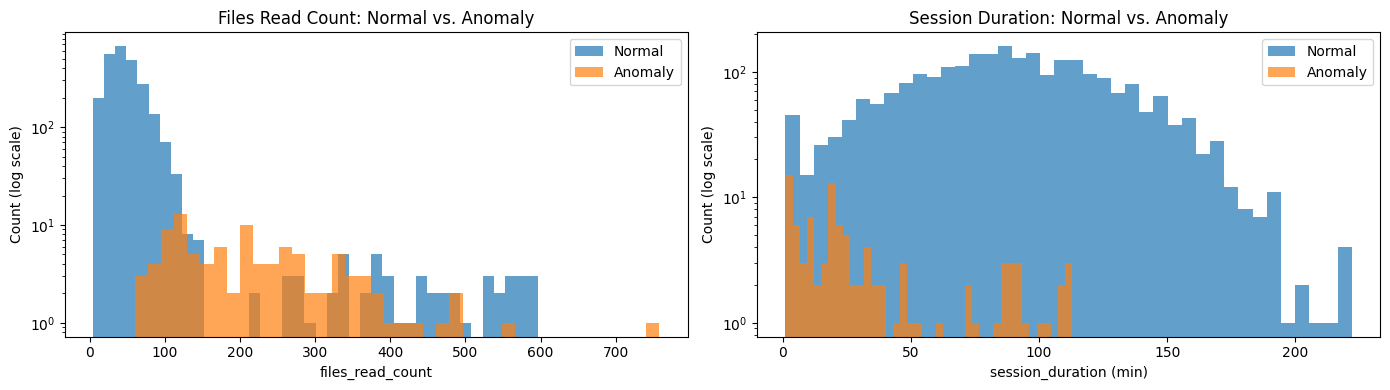

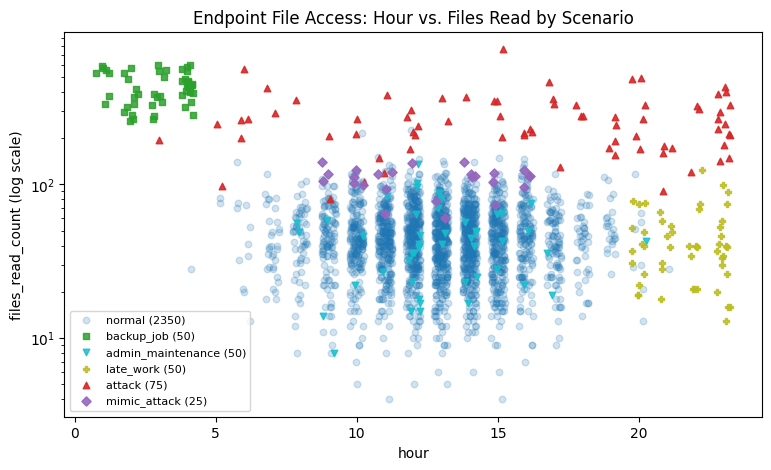

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(df[df["is_anomaly"] == 0]["files_read_count"], bins=40, alpha=0.7, label="Normal")
axes[0].hist(df[df["is_anomaly"] == 1]["files_read_count"], bins=40, alpha=0.7, label="Anomaly")
axes[0].set_yscale("log")
axes[0].set_xlabel("files_read_count")
axes[0].set_ylabel("Count (log scale)")
axes[0].set_title("Files Read Count: Normal vs. Anomaly")
axes[0].legend()

axes[1].hist(df[df["is_anomaly"] == 0]["session_duration"], bins=40, alpha=0.7, label="Normal")
axes[1].hist(df[df["is_anomaly"] == 1]["session_duration"], bins=40, alpha=0.7, label="Anomaly")
axes[1].set_yscale("log")
axes[1].set_xlabel("session_duration (min)")
axes[1].set_ylabel("Count (log scale)")
axes[1].set_title("Session Duration: Normal vs. Anomaly")
axes[1].legend()

plt.tight_layout()
plt.show()

# Scatter plot: Hour vs. Files Read by Scenario
styles = {
    "normal": dict(color="tab:blue", marker="o", alpha=0.2),
    "backup_job": dict(color="tab:green", marker="s", alpha=0.85),
    "admin_maintenance": dict(color="tab:cyan", marker="v", alpha=0.85),
    "late_work": dict(color="tab:olive", marker="P", alpha=0.85),
    "attack": dict(color="tab:red", marker="^", alpha=0.9),
    "mimic_attack": dict(color="tab:purple", marker="D", alpha=0.9),
}
jitter = np.random.default_rng(0).uniform(-0.25, 0.25, len(df))

plt.figure(figsize=(9, 5))
for name, st in styles.items():
    m = (scenario == name).to_numpy()
    plt.scatter(df.loc[m, "hour"] + jitter[m], df.loc[m, "files_read_count"], s=22, label=f"{name} ({m.sum()})", **st)
plt.yscale("log")
plt.xlabel("hour")
plt.ylabel("files_read_count (log scale)")
plt.title("Endpoint File Access: Hour vs. Files Read by Scenario")
plt.legend(fontsize=8)
plt.show()

### Interpreting the exploratory results

- **Normal behavior:** Typical sessions happen around midday (median `hour` = 13), last ~89 minutes, and read a median of 44 files across 9 folders.
- **Anomalous behavior:** Attack sessions tend to be much shorter (median `session_duration` = 21 min) with much higher file/folder activity (median 208 files across 50.5 folders).
- **Overlap & edge cases:** As shown in the scatter plot, legitimate `backup_job` events also have very high file counts (250–600) late at night, while `mimic_attack` events blend directly into normal working hours and file counts. Because no single threshold separates normal from attack, the models must learn combinations of features.
- **Why accuracy is misleading:** Since anomalies make up only **3.85%** of the data, a model that flags nothing would still get 96.15% accuracy. Later sections therefore focus on **precision, recall, F1, false positives, and false negatives**.

## 3. Shared train, validation and test split

The dataset (2,600 rows) is split into **60% train (1,560)**, **20% validation (520)**, and **20% test (520)**, stratified by `is_anomaly`. The Autoencoder is trained and validated **exclusively on normal records** (1,500 train / 500 validation) so it learns a baseline of benign behavior, while the test set (500 normal, 20 anomalies) is kept untouched to evaluate both models fairly.

> * **Note:** We filtered out attacks so the Autoencoder only trains on clean normal data, whereas in a real company it is hard to be 100% sure that past logs have no hidden attacks.

In [5]:
train_df, temp_df = train_test_split(df, test_size=0.40, stratify=df["is_anomaly"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["is_anomaly"], random_state=SEED)

normal_train_df = train_df[train_df["is_anomaly"] == 0].copy()
normal_val_df = val_df[val_df["is_anomaly"] == 0].copy()
y_test = test_df["is_anomaly"].to_numpy()

print("Train:", train_df.shape, "| Normal-only AE train:", normal_train_df.shape)
print("Validation:", val_df.shape, "| Normal-only AE val:", normal_val_df.shape)
print("Test:", test_df.shape)

display(pd.DataFrame({
    "train": scenario[train_df.index].value_counts(),
    "validation": scenario[val_df.index].value_counts(),
    "test": scenario[test_df.index].value_counts(),
}).fillna(0).astype(int))

Train: (1560, 9) | Normal-only AE train: (1500, 9)
Validation: (520, 9) | Normal-only AE val: (500, 9)
Test: (520, 9)


,train,validation,test
scenario,,,
admin_maintenance,30,10,10
attack,42,17,16
backup_job,33,7,10
late_work,28,13,9
mimic_attack,18,3,4
normal,1409,470,471


## 4. Model A — Isolation Forest

`contamination = 0.04` is set to match the 1–5% anomaly range specified in the lab instructions. It is chosen a priori and is **not** derived from the ground-truth labels, which are used only for evaluation

Contamination: 0.04
Flagged in test: 23 of 520 (4.42%)

Confusion Matrix:
 [[491   9]
 [  6  14]]

Classification Report:
               precision    recall  f1-score   support

      Normal       0.99      0.98      0.98       500
     Anomaly       0.61      0.70      0.65        20

    accuracy                           0.97       520
   macro avg       0.80      0.84      0.82       520
weighted avg       0.97      0.97      0.97       520



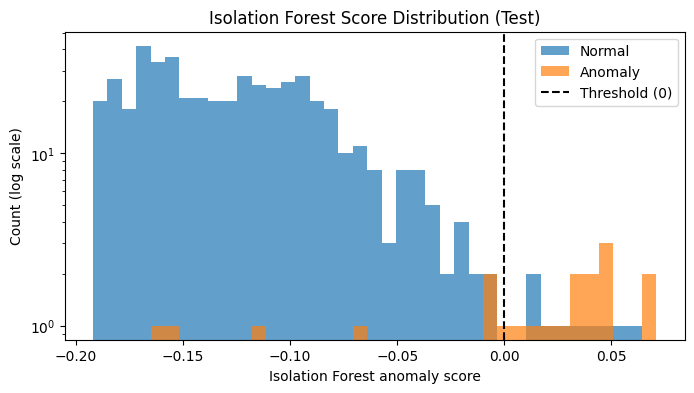

In [6]:
if_preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols),
])

X_if_train = if_preprocessor.fit_transform(train_df[numeric_cols + categorical_cols])
X_if_test = if_preprocessor.transform(test_df[numeric_cols + categorical_cols])

iso = IsolationForest(
    n_estimators=300,
    contamination=0.04,
    random_state=SEED,
    n_jobs=-1
)
iso.fit(X_if_train)

if_score = -iso.decision_function(X_if_test)  # Higher = more anomalous
if_pred = (iso.predict(X_if_test) == -1).astype(int)

print("Contamination:", round(iso.contamination, 4))
print(f"Flagged in test: {if_pred.sum()} of {len(if_pred)} ({if_pred.mean():.2%})")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, if_pred))
print("\nClassification Report:\n", classification_report(y_test, if_pred, target_names=["Normal", "Anomaly"], zero_division=0))

bins = np.linspace(if_score.min(), if_score.max(), 40)
plt.figure(figsize=(8, 4))
plt.hist(if_score[y_test == 0], bins=bins, alpha=0.7, label="Normal")
plt.hist(if_score[y_test == 1], bins=bins, alpha=0.7, label="Anomaly")
plt.axvline(0, color="black", linestyle="--", label="Threshold (0)")
plt.yscale("log")
plt.xlabel("Isolation Forest anomaly score")
plt.ylabel("Count (log scale)")
plt.title("Isolation Forest Score Distribution (Test)")
plt.legend()
plt.show()

### Reading the Isolation Forest output

On the test set (520 rows, 20 anomalies), Isolation Forest flagged **23 records (4.42%)**, achieving **Precision = 0.609**, **Recall = 0.700**, and **F1 = 0.651** (14 true positives, **9 false positives**, **6 false negatives**).

Isolation Forest is effective at catching events that are globally isolated in the feature space (such as high `files_read_count` and `folders_accessed_count`). However, because it relies on feature-space isolation, it also flags legitimate numeric outliers like overnight `backup_job` sessions.


## 5. Model B — Autoencoder with categorical embeddings

Each categorical feature (`process_name`, `user_role`, `target_share`) is mapped to a trainable embedding layer and concatenated with the scaled numeric features (`hour`, `is_weekend`, `session_duration`, `files_read_count`, `folders_accessed_count`). The decoder reconstructs:

- standardized numeric values using mean squared error (MSE);
- each categorical field using a softmax output (cross-entropy weighted by 0.35).

The anomaly score combines numeric reconstruction error and categorical reconstruction surprise.

A fixed 0.35 categorical loss weight and 150 epochs are used to keep this lab comparison simple, whereas real deployments tune these settings on historical incident data.

In [7]:
num_scaler = StandardScaler()
num_scaler.fit(normal_train_df[numeric_cols])

category_maps = {}
category_sizes = {}
for col in categorical_cols:
    values = sorted(train_df[col].astype(str).unique().tolist())
    category_maps[col] = {val: i + 1 for i, val in enumerate(values)}  # 0 = unknown
    category_sizes[col] = len(values) + 1

def prepare_ae_frame(frame):
    numeric = num_scaler.transform(frame[numeric_cols]).astype("float32")
    inputs = {"numeric": numeric}
    targets = {"numeric_out": numeric}
    for col in categorical_cols:
        indices = frame[col].astype(str).map(category_maps[col]).fillna(0).astype("int32").to_numpy()
        inputs[col] = indices
        targets[f"{col}_out"] = indices
    return inputs, targets

ae_train_inputs, ae_train_targets = prepare_ae_frame(normal_train_df)
ae_val_inputs, ae_val_targets = prepare_ae_frame(normal_val_df)
ae_test_inputs, ae_test_targets = prepare_ae_frame(test_df)
print("Category maps:", category_maps)

Category maps: {'process_name': {'chrome.exe': 1, 'cmd.exe': 2, 'excel.exe': 3, 'explorer.exe': 4, 'powershell.exe': 5, 'svchost.exe': 6, 'winword.exe': 7, 'wmic.exe': 8}, 'user_role': {'developer': 1, 'employee': 2, 'it_admin': 3, 'service_account': 4}, 'target_share': {'finance_vault': 1, 'hr_payroll': 2, 'public_docs': 3, 'sys_config': 4, 'team_drive': 5}}


In [8]:
numeric_input = layers.Input(shape=(len(numeric_cols),), name="numeric")
model_inputs = {"numeric": numeric_input}
parts = [numeric_input]

for col in categorical_cols:
    inp = layers.Input(shape=(), dtype="int32", name=col)
    model_inputs[col] = inp
    emb_dim = min(8, max(2, int(np.ceil(np.sqrt(category_sizes[col])))))
    emb = layers.Embedding(category_sizes[col], emb_dim, name=f"{col}_embedding")(inp)
    parts.append(layers.Flatten()(emb))

combined = layers.Concatenate(name="combined_features")(parts)
hidden = layers.Dense(32, activation="relu")(combined)
latent = layers.Dense(8, activation="relu", name="behavior_embedding")(hidden)
decoded = layers.Dense(32, activation="relu")(latent)

outputs = {"numeric_out": layers.Dense(len(numeric_cols), name="numeric_out")(decoded)}
for col in categorical_cols:
    outputs[f"{col}_out"] = layers.Dense(category_sizes[col], activation="softmax", name=f"{col}_out")(decoded)

autoencoder = keras.Model(inputs=model_inputs, outputs=outputs)
encoder = keras.Model(inputs=model_inputs, outputs=latent)

losses = {"numeric_out": "mse"}
loss_weights = {"numeric_out": 1.0}
for col in categorical_cols:
    losses[f"{col}_out"] = "sparse_categorical_crossentropy"
    loss_weights[f"{col}_out"] = 0.35

autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=losses,
    loss_weights=loss_weights
)
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ process_name        │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ user_role           │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ target_share        │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ process_name_embed… │ (None, 3)         │         27 │ process_name[0][… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ user_role_embedding │ (None, 3)         │         15 │ user_role[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ target_share_embed… │ (None, 3)         │         18 │ target_share[0][… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ numeric             │ (None, 5)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 3)         │          0 │ process_name_emb… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 3)         │          0 │ user_role_embedd… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_2 (Flatten) │ (None, 3)         │          0 │ target_share_emb… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ combined_features   │ (None, 14)        │          0 │ numeric[0][0],    │
│ (Concatenate)       │                   │            │ flatten[0][0],    │
│                     │                   │            │ flatten_1[0][0],  │
│                     │                   │            │ flatten_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │        480 │ combined_feature… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ behavior_embedding  │ (None, 8)         │        264 │ dense[0][0]       │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │        288 │ behavior_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ numeric_out (Dense) │ (None, 5)         │        165 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ process_name_out    │ (None, 9)         │        297 │ dense_1[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ target_share_out    │ (None, 6)         │        198 │ dense_1[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ user_role_out       │ (None, 5)         │        165 │ dense_1[0][0]     │
│ (Dense)             │                   │            │                 

 Total params: 1,917 (7.49 KB)

 Trainable params: 1,917 (7.49 KB)

 Non-trainable params: 0 (0.00 B)

Epochs run: 150
Best validation loss: 0.0117


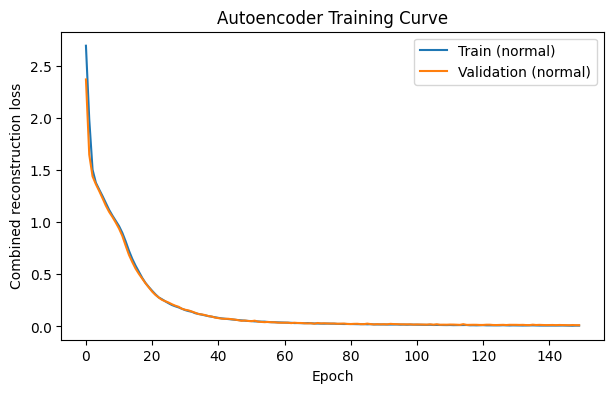

In [9]:
callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)]
history = autoencoder.fit(
    ae_train_inputs,
    ae_train_targets,
    validation_data=(ae_val_inputs, ae_val_targets),
    epochs=150,
    batch_size=32,
    shuffle=True,
    callbacks=callbacks,
    verbose=0
)

print("Epochs run:", len(history.history["loss"]))
print("Best validation loss:", round(min(history.history["val_loss"]), 4))

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Train (normal)")
plt.plot(history.history["val_loss"], label="Validation (normal)")
plt.xlabel("Epoch")
plt.ylabel("Combined reconstruction loss")
plt.title("Autoencoder Training Curve")
plt.legend()
plt.show()

### Interpreting the training curve

Both training and validation reconstruction losses decrease smoothly and remain close throughout the 150 epochs (best validation loss: **0.0117**). The small difference between the curves suggests no obvious signs of overfitting during this run, though similar loss curves do not guarantee that overfitting is completely absent. EarlyStopping was configured with a patience of 10 epochs, and the model ran for the full 150 epochs.

AE threshold (99th pct of normal val): 0.0982
Flagged in test: 21 of 520 (4.04%)

Confusion Matrix:
 [[495   5]
 [  4  16]]

Classification Report:
               precision    recall  f1-score   support

      Normal       0.99      0.99      0.99       500
     Anomaly       0.76      0.80      0.78        20

    accuracy                           0.98       520
   macro avg       0.88      0.90      0.89       520
weighted avg       0.98      0.98      0.98       520



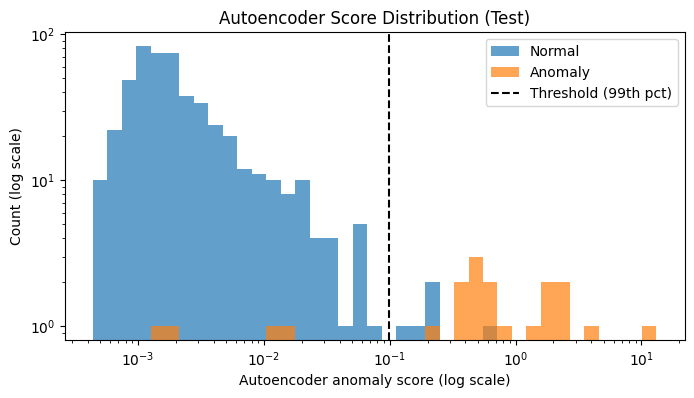

In [10]:
def ae_anomaly_scores(model, inputs, targets):
    preds = model.predict(inputs, verbose=0)
    num_err = np.mean(np.square(targets["numeric_out"] - preds["numeric_out"]), axis=1)
    cat_err = np.zeros(len(num_err), dtype="float32")
    eps = 1e-8
    for col in categorical_cols:
        true_idx = targets[f"{col}_out"].astype(int)
        probs = preds[f"{col}_out"]
        cat_err += -np.log(probs[np.arange(len(true_idx)), true_idx] + eps)
    cat_err /= len(categorical_cols)
    return num_err + 0.35 * cat_err

normal_val_score = ae_anomaly_scores(autoencoder, ae_val_inputs, ae_val_targets)
ae_score = ae_anomaly_scores(autoencoder, ae_test_inputs, ae_test_targets)

threshold = np.percentile(normal_val_score, 99)
ae_pred = (ae_score > threshold).astype(int)

print("AE threshold (99th pct of normal val):", round(threshold, 4))
print(f"Flagged in test: {ae_pred.sum()} of {len(ae_pred)} ({ae_pred.mean():.2%})")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, ae_pred))
print("\nClassification Report:\n", classification_report(y_test, ae_pred, target_names=["Normal", "Anomaly"], zero_division=0))

bins = np.logspace(np.log10(max(1e-4, min(ae_score.min(), normal_val_score.min()))), np.log10(ae_score.max()), 40)
plt.figure(figsize=(8, 4))
plt.hist(ae_score[y_test == 0], bins=bins, alpha=0.7, label="Normal")
plt.hist(ae_score[y_test == 1], bins=bins, alpha=0.7, label="Anomaly")
plt.axvline(threshold, color="black", linestyle="--", label="Threshold (99th pct)")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Autoencoder anomaly score (log scale)")
plt.ylabel("Count (log scale)")
plt.title("Autoencoder Score Distribution (Test)")
plt.legend()
plt.show()

In [11]:
latent_vectors = encoder.predict(ae_test_inputs, verbose=0)
print("Latent embeddings shape:", latent_vectors.shape)
display(pd.DataFrame(latent_vectors[:5], index=test_df.index[:5]).round(3))

Latent embeddings shape: (520, 8)


,0,1,2,3,4,5,6,7
1881,13.169000,15.838000,16.423000,10.311000,6.191000,8.017000,10.185,15.953000
2218,31.076000,16.551001,26.622000,18.750999,22.214001,26.190001,19.983,26.243999
1729,14.996000,10.614000,8.246000,12.881000,10.652000,15.575000,13.427,6.866000
528,16.858999,19.802999,19.886999,15.984000,11.138000,14.815000,14.714,24.886000
2098,29.304001,13.815000,26.288000,16.732000,23.372999,28.493000,20.774,35.972000


### Reading the autoencoder output

Using the **99th percentile of normal validation scores (0.0982)** as the alert threshold, the Autoencoder flagged **21 test records (4.04%)**, achieving **Precision = 0.762**, **Recall = 0.800**, and **F1 = 0.780** (16 true positives, **5 false positives**, **4 false negatives**).

Because the model was trained only on normal behavior—including legitimate exceptions like `backup_job` and `admin_maintenance`—it learned which combinations of `process_name`, `user_role`, and `target_share` are normal, allowing it to catch more attacks while raising fewer false alarms than Isolation Forest.

## 6. Quantitative comparison

In [12]:
def metric_row(name, pred):
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, pred, average="binary", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {
        "model": name,
        "detected_anomalies": int(pred.sum()),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "false_positives": int(fp),
        "false_negatives": int(fn)
    }

comparison = pd.DataFrame([
    metric_row("Isolation Forest", if_pred),
    metric_row("Autoencoder + embeddings", ae_pred)
]).set_index("model")
display(comparison.round(3))

agreement = np.mean(if_pred == ae_pred)
print(f"Agreement rate: {agreement:.2%}")
print("Flagged by both:", int(np.sum((if_pred == 1) & (ae_pred == 1))))
print("Isolation Forest only:", int(np.sum((if_pred == 1) & (ae_pred == 0))))
print("Autoencoder only:", int(np.sum((if_pred == 0) & (ae_pred == 1))))

test_scenario = scenario[test_df.index]
print("\nBreakdown by hidden scenario:")
display(pd.DataFrame({
    "rows_in_test": test_scenario.value_counts(),
    "flagged_by_IF": test_scenario[if_pred == 1].value_counts(),
    "flagged_by_AE": test_scenario[ae_pred == 1].value_counts(),
}).fillna(0).astype(int))

,detected_anomalies,precision,recall,f1,false_positives,false_negatives
model,,,,,,
Isolation Forest,23,0.609,0.7,0.651,9,6
Autoencoder + embeddings,21,0.762,0.8,0.780,5,4


Agreement rate: 97.69%
Flagged by both: 16
Isolation Forest only: 7
Autoencoder only: 5

Breakdown by hidden scenario:


,rows_in_test,flagged_by_IF,flagged_by_AE
scenario,,,
admin_maintenance,10,0,1
attack,16,14,16
backup_job,10,9,2
late_work,9,0,0
mimic_attack,4,0,0
normal,471,0,2


### Comparing the methods

| Measure | Isolation Forest | Autoencoder + embeddings |
| :--- | :---: | :---: |
| **Detected anomalies** | 23 | 21 |
| **Precision** | 0.609 | 0.762 |
| **Recall** | 0.700 | 0.800 |
| **F1 score** | 0.651 | 0.780 |
| **False positives** | 9 | 5 |
| **False negatives** | 6 | 4 |

- **Agreement rate:** **97.69%** (508 of 520 test records)
- **Anomalies detected by both models:** **16**
- **Anomalies detected only by Isolation Forest:** **7**
- **Anomalies detected only by the Autoencoder:** **5**

**Scenario breakdown:**
- The Autoencoder caught **all 16 regular attacks**, whereas Isolation Forest caught **14**.
- Isolation Forest flagged **9 of 10** legitimate `backup_job` events as false positives, while the Autoencoder only flagged **2**.
- Neither model caught the **4 `mimic_attack`** records, which were designed to blend into normal working hours and file-read ranges.

In [13]:
# Automatic interpretation of the comparison table
best_precision = comparison["precision"].idxmax()
best_recall = comparison["recall"].idxmax()
best_f1 = comparison["f1"].idxmax()
fewest_fp = comparison["false_positives"].idxmin()
fewest_fn = comparison["false_negatives"].idxmin()

print("RESULT INTERPRETATION")
print("- Highest precision:", best_precision)
print("- Highest recall:", best_recall)
print("- Highest F1:", best_f1)
print("- Fewest false positives:", fewest_fp)
print("- Fewest false negatives:", fewest_fn)

if best_precision == best_recall == best_f1:
    print(f"\n{best_f1} is strongest on the main summary metrics for this run.")
else:
    print("\nNo single model dominates every criterion. Select a model according to the operational cost of false alerts versus missed attacks.")

print("\nRecommended triage rule:")
print("1. Prioritize events detected by both models.")
print("2. Review model-disagreement events manually.")
print("3. Treat events rejected by both as lower priority, not guaranteed benign.")


RESULT INTERPRETATION
- Highest precision: Autoencoder + embeddings
- Highest recall: Autoencoder + embeddings
- Highest F1: Autoencoder + embeddings
- Fewest false positives: Autoencoder + embeddings
- Fewest false negatives: Autoencoder + embeddings

Autoencoder + embeddings is strongest on the main summary metrics for this run.

Recommended triage rule:
1. Prioritize events detected by both models.
2. Review model-disagreement events manually.
3. Treat events rejected by both as lower priority, not guaranteed benign.


## 7. Original feature space versus behavioral embedding space

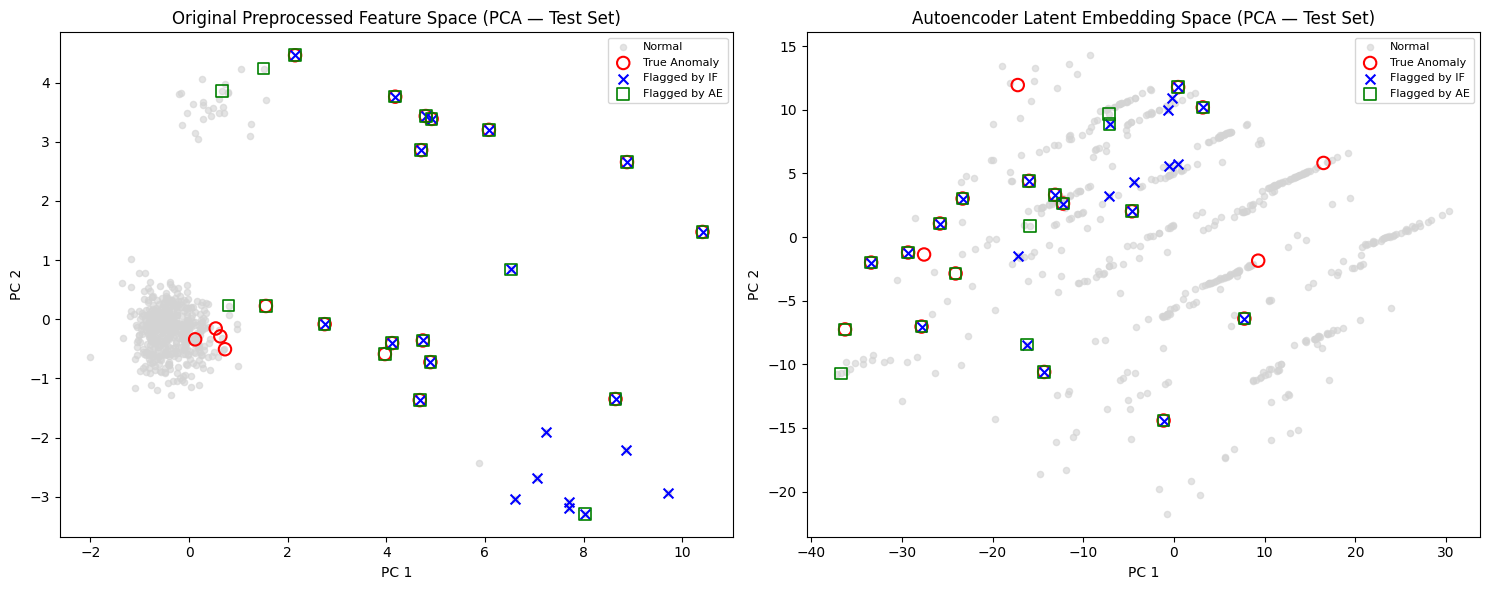

In [14]:
pca_orig = PCA(n_components=2, random_state=SEED).fit_transform(X_if_test)
pca_latent = PCA(n_components=2, random_state=SEED).fit_transform(latent_vectors)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, coords, title in [
    (axes[0], pca_orig, "Original Preprocessed Feature Space (PCA — Test Set)"),
    (axes[1], pca_latent, "Autoencoder Latent Embedding Space (PCA — Test Set)")
]:
    ax.scatter(coords[y_test == 0, 0], coords[y_test == 0, 1], c="lightgrey", s=20, alpha=0.6, label="Normal")
    ax.scatter(coords[y_test == 1, 0], coords[y_test == 1, 1], facecolors="none", edgecolors="red", s=80, lw=1.5, label="True Anomaly")
    ax.scatter(coords[if_pred == 1, 0], coords[if_pred == 1, 1], c="blue", marker="x", s=50, label="Flagged by IF")
    ax.scatter(coords[ae_pred == 1, 0], coords[ae_pred == 1, 1], facecolors="none", edgecolors="green", marker="s", s=70, lw=1.2, label="Flagged by AE")
    ax.set_title(title)
    ax.set_xlabel("PC 1")
    ax.set_ylabel("PC 2")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

### Interpreting the PCA visualizations

Looking directly at the two 2D PCA projections of the test set:

- **Original feature space (left):** Normal records form a tight cluster on the left (`PC 1 ≈ 0`), while Isolation Forest's `backup_job` false positives (blue `x` marks) sit isolated at the bottom right (`PC 1 ≈ 6–10`, `PC 2 ≈ -2 to -3`). Most true attacks spread across the upper right, while the 4 missed `mimic_attack` records (red circles) sit directly inside the main normal cluster.
- **Autoencoder latent space (right):** Normal records spread diagonally across the 2D projection, with flagged anomalies scattered along the outer bands rather than forming a single isolated cluster.

Visually, the 2D PCA projection of the latent space does **not** separate anomalies more cleanly than the original feature space. However, as noted in the lab guidelines, compressing an 8-dimensional latent space into 2 dimensions discards information—so visual overlap in 2D does not indicate model failure, as confirmed by the Autoencoder's stronger quantitative metrics (F1 **0.780** vs. **0.651**).

## 8. Inspect model disagreements

In [15]:
inspect_df = test_df.copy()
inspect_df["scenario"] = test_scenario
inspect_df["if_score"] = np.round(if_score, 4)
inspect_df["if_pred"] = if_pred
inspect_df["ae_score"] = np.round(ae_score, 4)
inspect_df["ae_pred"] = ae_pred

disagreements = inspect_df[inspect_df["if_pred"] != inspect_df["ae_pred"]]
print(f"Total disagreements in test set: {len(disagreements)}")
display(disagreements.sort_values("ae_score", ascending=False))

print("\nTop 5 highest-scoring alerts (by Autoencoder):")
display(inspect_df.sort_values("ae_score", ascending=False).head(5))

Total disagreements in test set: 12


,hour,is_weekend,session_duration,files_read_count,folders_accessed_count,process_name,user_role,target_share,is_anomaly,scenario,if_score,if_pred,ae_score,ae_pred
598,16,0,22,219,17,powershell.exe,developer,hr_payroll,1,attack,-0.0092,0,0.5392,1
2380,13,0,18,260,60,powershell.exe,employee,hr_payroll,1,attack,-0.0086,0,0.4928,1
262,13,1,59,44,8,svchost.exe,employee,public_docs,0,normal,-0.0796,0,0.2406,1
1135,14,1,1,53,20,svchost.exe,it_admin,team_drive,0,normal,-0.0171,0,0.2160,1
175,12,0,17,136,9,cmd.exe,it_admin,sys_config,0,admin_maintenance,-0.0289,0,0.1132,1
2494,1,0,132,533,80,svchost.exe,service_account,team_drive,0,backup_job,0.0225,1,0.0336,0
2579,4,0,73,579,117,svchost.exe,service_account,public_docs,0,backup_job,0.0409,1,0.0326,0
486,4,0,9,473,112,svchost.exe,service_account,team_drive,0,backup_job,0.0442,1,0.0306,0
2168,4,0,147,440,105,svchost.exe,service_account,team_drive,0,backup_job,0.0271,1,0.0240,0
2284,2,0,137,282,107,svchost.exe,service_account,team_drive,0,backup_job,0.0165,1,0.0218,0



Top 5 highest-scoring alerts (by Autoencoder):


,hour,is_weekend,session_duration,files_read_count,folders_accessed_count,process_name,user_role,target_share,is_anomaly,scenario,if_score,if_pred,ae_score,ae_pred
889,15,1,21,758,54,wmic.exe,employee,sys_config,1,attack,0.0644,1,13.1458,1
2401,7,1,18,425,143,powershell.exe,employee,hr_payroll,1,attack,0.0710,1,4.2864,1
2139,16,0,1,116,113,powershell.exe,it_admin,team_drive,1,attack,0.0068,1,2.6567,1
2287,23,1,36,249,61,powershell.exe,it_admin,team_drive,1,attack,0.0439,1,2.1721,1
580,11,0,1,380,34,cmd.exe,it_admin,team_drive,1,attack,0.0001,1,1.9039,1


### How to investigate disagreements

The **12 disagreement records** in the test set (97.69% agreement) highlight the operational differences between the two models:

- **Isolation Forest only (7 records):** All 7 are legitimate overnight `backup_job` sessions (`svchost.exe`, `service_account`, high file/folder counts) that appear isolated numerically but were recognized as normal by the Autoencoder.
- **Autoencoder only (5 records):** Includes **2 true attacks** (rows `598` and `2380`) where the combination of process, role, and sensitive share was abnormal, plus **3 false positives** (1 `admin_maintenance` and 2 `normal` records).

Attack row `580` is also in the Autoencoder's top-5 scores, but Isolation Forest flagged it as well, so it is not a disagreement.

In a real SOC, ground-truth labels are not available, so analysts prioritize alerts flagged by both models and manually investigate disagreements using operational context.


## 9. Student Interpretation (Human–AI Decision Task)

### Part A — Three model-disagreement records

(The ground-truth label in each heading is shown for reference only; the analyst decision is based on the visible evidence.)

#### 1. Row `598` — Flagged by Autoencoder only (ground truth: attack)
* **Record Details:** `hour=16`, `is_weekend=0`, `session_duration=22`, `files_read_count=219`, `folders_accessed_count=17`, `process_name=powershell.exe`, `user_role=developer`, `target_share=hr_payroll`. Scores: AE `0.5392` (threshold `0.0982`), IF `-0.0092` (not flagged).
* **Supporting Evidence:** A `developer` account running `powershell.exe` to read 219 files across 17 folders in the sensitive `hr_payroll` share during a short 22-minute session.
* **Possible False Positive:** Could be an authorized developer running a data-migration or HR reporting script; access to `hr_payroll` would be unusual for a developer role in a typical organization.
* **SOC Decision:** **Accept / Escalate.** Even though the numeric values were not extreme enough to trigger Isolation Forest, the combination of `developer` + `powershell.exe` + `hr_payroll` is highly suspicious and should be escalated to Tier 2 to verify authorization.
* **MITRE ATT&CK Link:** **T1083 (File and Directory Discovery)** — using a scripting interpreter to rapidly enumerate files in a sensitive share.

#### 2. Row `2494` — Flagged by Isolation Forest only (ground truth: legitimate `backup_job`)
* **Record Details:** `hour=1`, `is_weekend=0`, `session_duration=132`, `files_read_count=533`, `folders_accessed_count=80`, `process_name=svchost.exe`, `user_role=service_account`, `target_share=team_drive`. Scores: IF `0.0225` (flagged), AE `0.0336` (below threshold).
* **Supporting Evidence:** Very high file and folder counts (`533` files, `80` folders) at 1:00 AM. Isolation Forest flagged it because those numeric values are extreme global outliers.
* **Possible False Positive:** Scheduled overnight backup activity performed by a `service_account` using `svchost.exe` over a normal 132-minute window. The Autoencoder learned this legitimate pattern from the normal training data and correctly ignored it.
* **SOC Decision:** **Challenge / Close (after verifying backup schedule).** Confirm that `service_account` is on the approved overnight backup schedule; if so, close as a false positive.
* **MITRE ATT&CK Link:** Resembles high-volume **T1083 (File and Directory Discovery)** on paper, which is why human context (maintenance/backup schedules) is required to avoid alert fatigue.

#### 3. Row `175` — Flagged by Autoencoder only (ground truth: legitimate `admin_maintenance`)
* **Record Details:** `hour=12`, `is_weekend=0`, `session_duration=17`, `files_read_count=136`, `folders_accessed_count=9`, `process_name=cmd.exe`, `user_role=it_admin`, `target_share=sys_config`. Scores: AE `0.1132` (only just above the `0.0982` threshold), IF `-0.0289` (not flagged).
* **Supporting Evidence:** Short 17-minute session using `cmd.exe` to read 136 files in `sys_config`. The score is only marginally above the threshold, so this is a weak alert.
* **Possible False Positive:** Routine midday system maintenance by an `it_admin` account working in `sys_config` during normal business hours (`hour=12`, weekday).
* **SOC Decision:** **Request Context / Challenge.** Check for an open IT change ticket for `it_admin`. Because the role, share, and time of day align with normal administrative work, this is likely benign unless no maintenance was scheduled.
* **MITRE ATT&CK Link:** Command-line file access in `sys_config` can overlap with **T1083 (File and Directory Discovery)** if an admin account is compromised.


### Part B — Three highest-scoring alerts (Autoencoder)

#### 1. Row `889` — AE Score `13.1458` (flagged by both; ground truth: attack)
* **Record Details:** `hour=15`, `is_weekend=1`, `session_duration=21`, `files_read_count=758`, `folders_accessed_count=54`, `process_name=wmic.exe`, `user_role=employee`, `target_share=sys_config`.
* **Supporting Evidence:** Highest score in the test set (`13.1458`, about 130× the `0.0982` threshold). An `employee` account using the administrative tool `wmic.exe` read 758 files (the largest count in the test set) from `sys_config` on a weekend, in a short 21-minute session.
* **Possible False Positive:** An emergency administrative script or an unscheduled bulk audit, though a regular `employee` using `wmic.exe` on `sys_config` makes benign activity unlikely.
* **SOC Decision:** **Accept / Escalate immediately.** High-confidence alert flagged by both models; isolate or investigate the account and verify command-line history.
* **MITRE ATT&CK Link:** **T1083 (File and Directory Discovery)** — rapid, high-volume enumeration of files and directories.

#### 2. Row `2401` — AE Score `4.2864` (flagged by both; ground truth: attack)
* **Record Details:** `hour=7`, `is_weekend=1`, `session_duration=18`, `files_read_count=425`, `folders_accessed_count=143`, `process_name=powershell.exe`, `user_role=employee`, `target_share=hr_payroll`.
* **Supporting Evidence:** Second-highest score (`4.2864`). An `employee` account ran `powershell.exe` across 143 folders in the sensitive `hr_payroll` share at 07:00 on a weekend, well outside the typical working-hour pattern.
* **Possible False Positive:** Authorized bulk file transfer or payroll preparation work done outside normal hours.
* **SOC Decision:** **Accept / Escalate.** Flagged by both models with a strong anomaly score; escalate to Tier 2 to confirm whether the user initiated the session.
* **MITRE ATT&CK Link:** **T1083 (File and Directory Discovery)**.

#### 3. Row `2139` — AE Score `2.6567` (flagged by both; ground truth: attack)
* **Record Details:** `hour=16`, `is_weekend=0`, `session_duration=1`, `files_read_count=116`, `folders_accessed_count=113`, `process_name=powershell.exe`, `user_role=it_admin`, `target_share=team_drive`.
* **Supporting Evidence:** Third-highest score (`2.6567`, far above the `0.0982` threshold). A 1-minute session touched 113 folders for only 116 files (about one file per folder), which looks like a fast breadth-first directory sweep rather than normal work.
* **Possible False Positive:** An `it_admin` account running a legitimate permissions audit or inventory script during business hours is plausible, and Isolation Forest's score for this record is only marginally positive (`0.0068`).
* **SOC Decision:** **Escalate for verification.** Both models flagged it, but because the role and time are consistent with admin work, confirm with the account owner and review endpoint process logs before treating it as malicious.
* **MITRE ATT&CK Link:** **T1083 (File and Directory Discovery)**.


## 10. Conclusion

1. **Which model performed better (and by which measure)?**  
   On this dataset and with these settings, the **Autoencoder with categorical embeddings** performed better across every summary metric: **F1 score 0.780 vs. 0.651**, **Precision 0.762 vs. 0.609**, and **Recall 0.800 vs. 0.700**. This is a single run on a test set with only 20 anomalies, so the gap (a few records) should not be read as a general ranking of the two methods.

2. **Which model produced fewer false positives?**  
   The **Autoencoder** produced fewer false positives (**5 vs. 9**). Isolation Forest flagged **9 out of 10** legitimate `backup_job` events because their high file/folder counts and late hours looked like numeric outliers, whereas the Autoencoder learned that `service_account` + `svchost.exe` overnight is normal and only flagged 2 of them.

3. **What types of anomalies were unique to each model?**  
   * **Autoencoder only:** Caught **all 16 regular attacks** (2 more than Isolation Forest, which caught 14), including contextual attacks like rows `598` and `2380` where the combination of process, role, and sensitive share violated normal behavior even when numeric counts were moderate.
   * **Isolation Forest only:** Did not catch any unique true attacks in this split; its 7 unique alerts were all `backup_job` false positives driven by extreme numeric values.
   * **Missed by both:** Neither model caught the 4 `mimic_attack` records, which is expected because those attacks intentionally blended into normal working hours, processes, and file-read ranges.

4. **Did the behavioral embeddings improve separation in the PCA plots?**  
   Not visually in 2D PCA—the original feature space actually shows tighter normal clustering, whereas the 2D projection of the 8D latent space spreads normal and anomalous points across diagonal bands. However, the Autoencoder's higher F1 (**0.780 vs. 0.651**) and fewer false positives (**5 vs. 9**) show that the embeddings still captured useful behavioral relationships in the full 8D space that 2D PCA compresses away.

5. **Why should a SOC analyst avoid relying on a single model?**  
   Every detector has blind spots and trade-offs: Isolation Forest is sensitive to legitimate numeric extremes (causing alert fatigue on backups), while an Autoencoder trained on synthetic or incomplete normal data can still raise false alarms on rare benign admin tasks or miss stealthy mimic attacks. Combining both models—prioritizing the **16 alerts flagged by both**, manually triaging the **12 disagreements**, and validating with human context (such as backup schedules and IT tickets)—produces more reliable SOC decisions.